# 03/17 — The slide confound: what it is, how big it is, what survives

One-stop overview of every analysis that touches the treatment × slide confound. This notebook only **loads
saved outputs** from the analyses listed below (plus one small live computation in section 5); re-run those to
regenerate.

| thread | where | outputs |
|---|---|---|
| microglia abundance | `09c-spatial-pie-maps`, `11-inflammation-results` | `results/tables/deconvolution_microglia/`, `results/inflammation/` |
| microglia state (inflammation) | `10*.py`, `11-inflammation-results` | `results/inflammation/tables/` |
| treatment classifier | `12-treatment-classifier.py` | `results/classifier*/` |
| within-section niche contrasts | `13-within-section-contrasts.py` | `results/within_section/` |
| regional rescue: within-section + slide removal | `14-*.py`, `15-*.py`, `16-slide-confound-rescue` | `results/within_section_rescue/`, `results/slide_removal/` |

## Bottom line

**It is the largest limitation of the study.** Every BRICHOS-vs-PBS comparison is largely also a slide
P24215-vs-P28052 comparison. The only within-slide treatment contrast is one BRICHOS section (P28052_401) vs
six PBS — n = 1.

| finding | status after slide checks |
|---|---|
| AD disease response (PIG / DAM up vs WT) | **robust** — present within sections and on the WT's own slide |
| BRICHOS lowers microglia abundance | **gone** — −5 % → +1 % with slide in the model (p = 0.70) |
| BRICHOS shifts microglia to homeostatic state | **weakened** — p 0.013 → 0.30 with slide; weak same-direction trend within sections |
| BRICHOS calms plaque-niche microglia (DAM/PIG) | **not supported** — 401 has the strongest niche response on its slide |
| a classifier can tell PBS from BRICHOS | **learns slide / depth**, not treatment |
| regional rescue (manuscript headline) | **partly survives** — infragranular cortex holds after control-gene slide removal (p 0.012–0.024), but rests on the two P24215 BRICHOS sections; 401 does not show it |
| original rescue-slope statistics | **not usable as-is** — slide alone produces a rescue-like slope |

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
warnings.filterwarnings('ignore')

ROOT = Path.cwd().resolve()
while not (ROOT / 'utils').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from utils.gene_sets import PIG_CHEN2020

RES = ROOT / 'results'
TBL = RES / 'tables' / 'attenuation'
pd.set_option('display.width', 200); pd.set_option('display.precision', 3)

## 1. The design problem

All six PBS sections are on slide P28052; two of three BRICHOS sections and the only WT are on P24215.

In [2]:
meta = pd.read_csv(TBL / 'pseudobulk_meta.tsv', sep='\t', index_col=0)
sec = meta.groupby('sample').agg(treatment=('treatment', 'first'), n_spots=('n_spots', 'sum'))
sec['slide'] = sec.index.str[:6]
display(pd.crosstab(sec.treatment, sec.slide).loc[['WT', 'PBS', 'BRICHOS']])
display(sec[['slide', 'treatment', 'n_spots']])

slide,P24215,P28052
treatment,,
WT,1,0
PBS,0,6
BRICHOS,2,1


,slide,treatment,n_spots
sample,,,
P24215_101,P24215,WT,2945
P24215_201,P24215,BRICHOS,2881
P24215_301,P24215,BRICHOS,2200
P28052_102,P28052,PBS,2640
P28052_103,P28052,PBS,2569
P28052_201,P28052,PBS,2356
P28052_202,P28052,PBS,2404
P28052_203,P28052,PBS,2558
P28052_301,P28052,PBS,2523


Sequencing depth tracks slide as well (from 03/12): P24215 sections ≈ 9.5–12 k median UMI/spot, P28052 PBS
≈ 13.5–20 k, and 401 is the shallowest P28052 section (≈ 12.2 k). Depth is removable by downsampling; slide is
not (see section 4).

**Consequence.** Slide and treatment are not separately identifiable from the data alone. With slide in a
model, the treatment estimate rests entirely on 401 vs the P28052 PBS sections. Batch-correction tools
(ComBat, Harmony, …) either remove the treatment effect with the slide or, if treatment is "protected",
inflate it (Nygaard et al. 2016).

## 2. Microglia abundance (cell2location, microglia-only run)

,comparison,rel_diff_pct,p,test
0,"BRICHOS vs PBS, whole section",-4.992,0.381,"MWU, 3 vs 6 sections"
1,"BRICHOS vs PBS, region-standardised",-5.206,0.262,"MWU, 3 vs 6 sections"
2,"BRICHOS vs PBS, region-adjusted",-5.206,0.071,"mixed model, section x region"
3,"BRICHOS vs PBS, region + slide-adjusted",1.231,0.703,"mixed model, section x region"
4,"BRICHOS 401 vs PBS, same slide, region-standar...",1.231,NaN,"n = 1, descriptive"


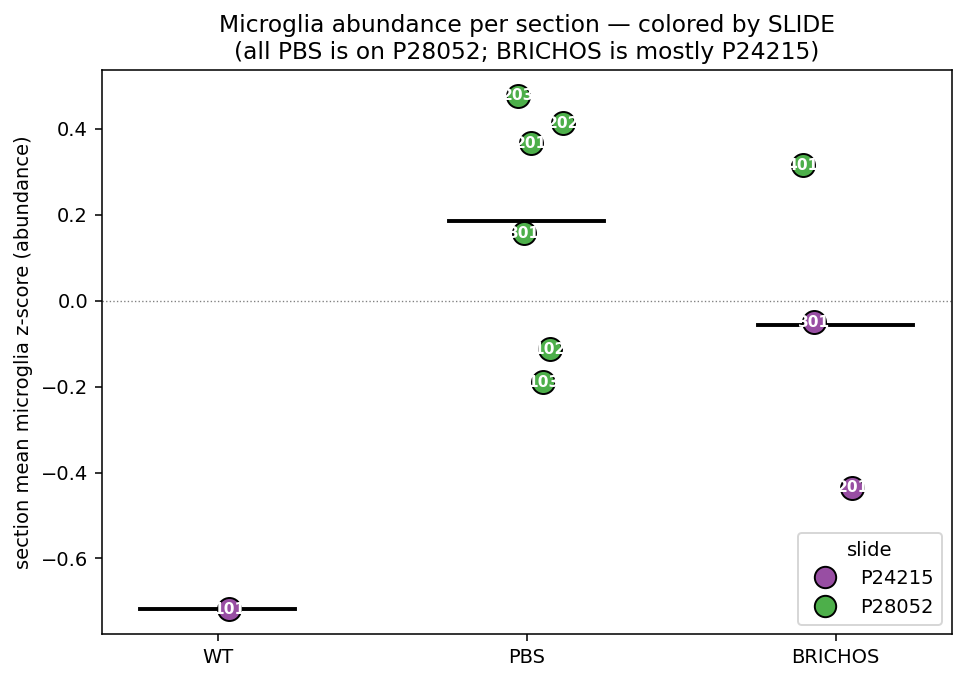

In [3]:
display(pd.read_csv(RES / 'tables' / 'deconvolution_microglia' / 'microglia_abundance_region_matched.csv'))
display(Image(RES / 'inflammation' / 'figs' / 'abundance_slide_confound.png'))

**Reading.** The apparent −5 % BRICHOS effect becomes +1 % once slide is in the model, and 401 sits inside
the PBS range. P24215 sections are low in every region, WT included. **No BRICHOS effect on microglia
abundance; the −5 % is slide P24215.**

## 3. Microglia state (homeostatic vs DAM)

### 3a. Hotspot mixed model, with and without slide (03/10–11)

In [4]:
display(pd.read_csv(RES / 'inflammation' / 'tables' / 'state_slide_adjusted.csv').set_index('metric'))

,beta_unadj,p_unadj,beta_slideadj,se_slideadj,p_slideadj
metric,,,,,
Homeostatic,0.077,0.013,0.045,0.043,0.301
DAM,0.033,0.405,0.029,0.059,0.629
DAMratio,-0.040,0.056,-0.013,0.026,0.615


### 3b. Within-section niche contrasts (03/13)

Within each section × region: microglia-hot spots minus cold spots, depth-matched. Section-wide slide/depth
shifts cancel. Positive controls (DAM/PIG) should be > 0 in AD; negative controls (neg_*) should not differ by
treatment.

hot − cold difference:


,WT,PBS_mean,BRICHOS_mean,delta,MWU_p,lmm_p,rank401_in_P28052,P24215_BRI_minus_WT
score,,,,,,,,
DAMratio,-0.162,-0.070,-0.082,-0.012,0.548,0.364,5,0.070
Homeostatic,0.182,0.238,0.257,0.018,0.262,0.264,2,0.068
DAM,0.020,0.169,0.175,0.006,1.000,0.722,1,0.138
PIG,0.075,0.221,0.236,0.016,0.381,0.449,1,0.150
MGnD,0.020,0.141,0.152,0.010,0.905,0.555,1,0.115
Neuroinflammation,0.004,0.011,0.010,-0.001,1.000,0.781,5,0.004
Complement,0.155,0.286,0.289,0.003,0.714,0.908,5,0.135
ReactiveAstro,0.008,0.037,0.033,-0.005,0.548,0.704,4,0.021
neg_Neuronal,-0.040,-0.025,-0.035,-0.010,0.548,0.436,2,0.013


slope on microglia rank (Homeostatic / DAMratio only):


,WT,PBS_mean,BRICHOS_mean,delta,MWU_p,lmm_p,rank401_in_P28052,P24215_BRI_minus_WT
score,,,,,,,,
DAMratio,-0.220,-0.091,-0.127,-0.035,0.262,0.073,3,0.085
Homeostatic,0.227,0.298,0.332,0.035,0.095,0.068,1,0.096


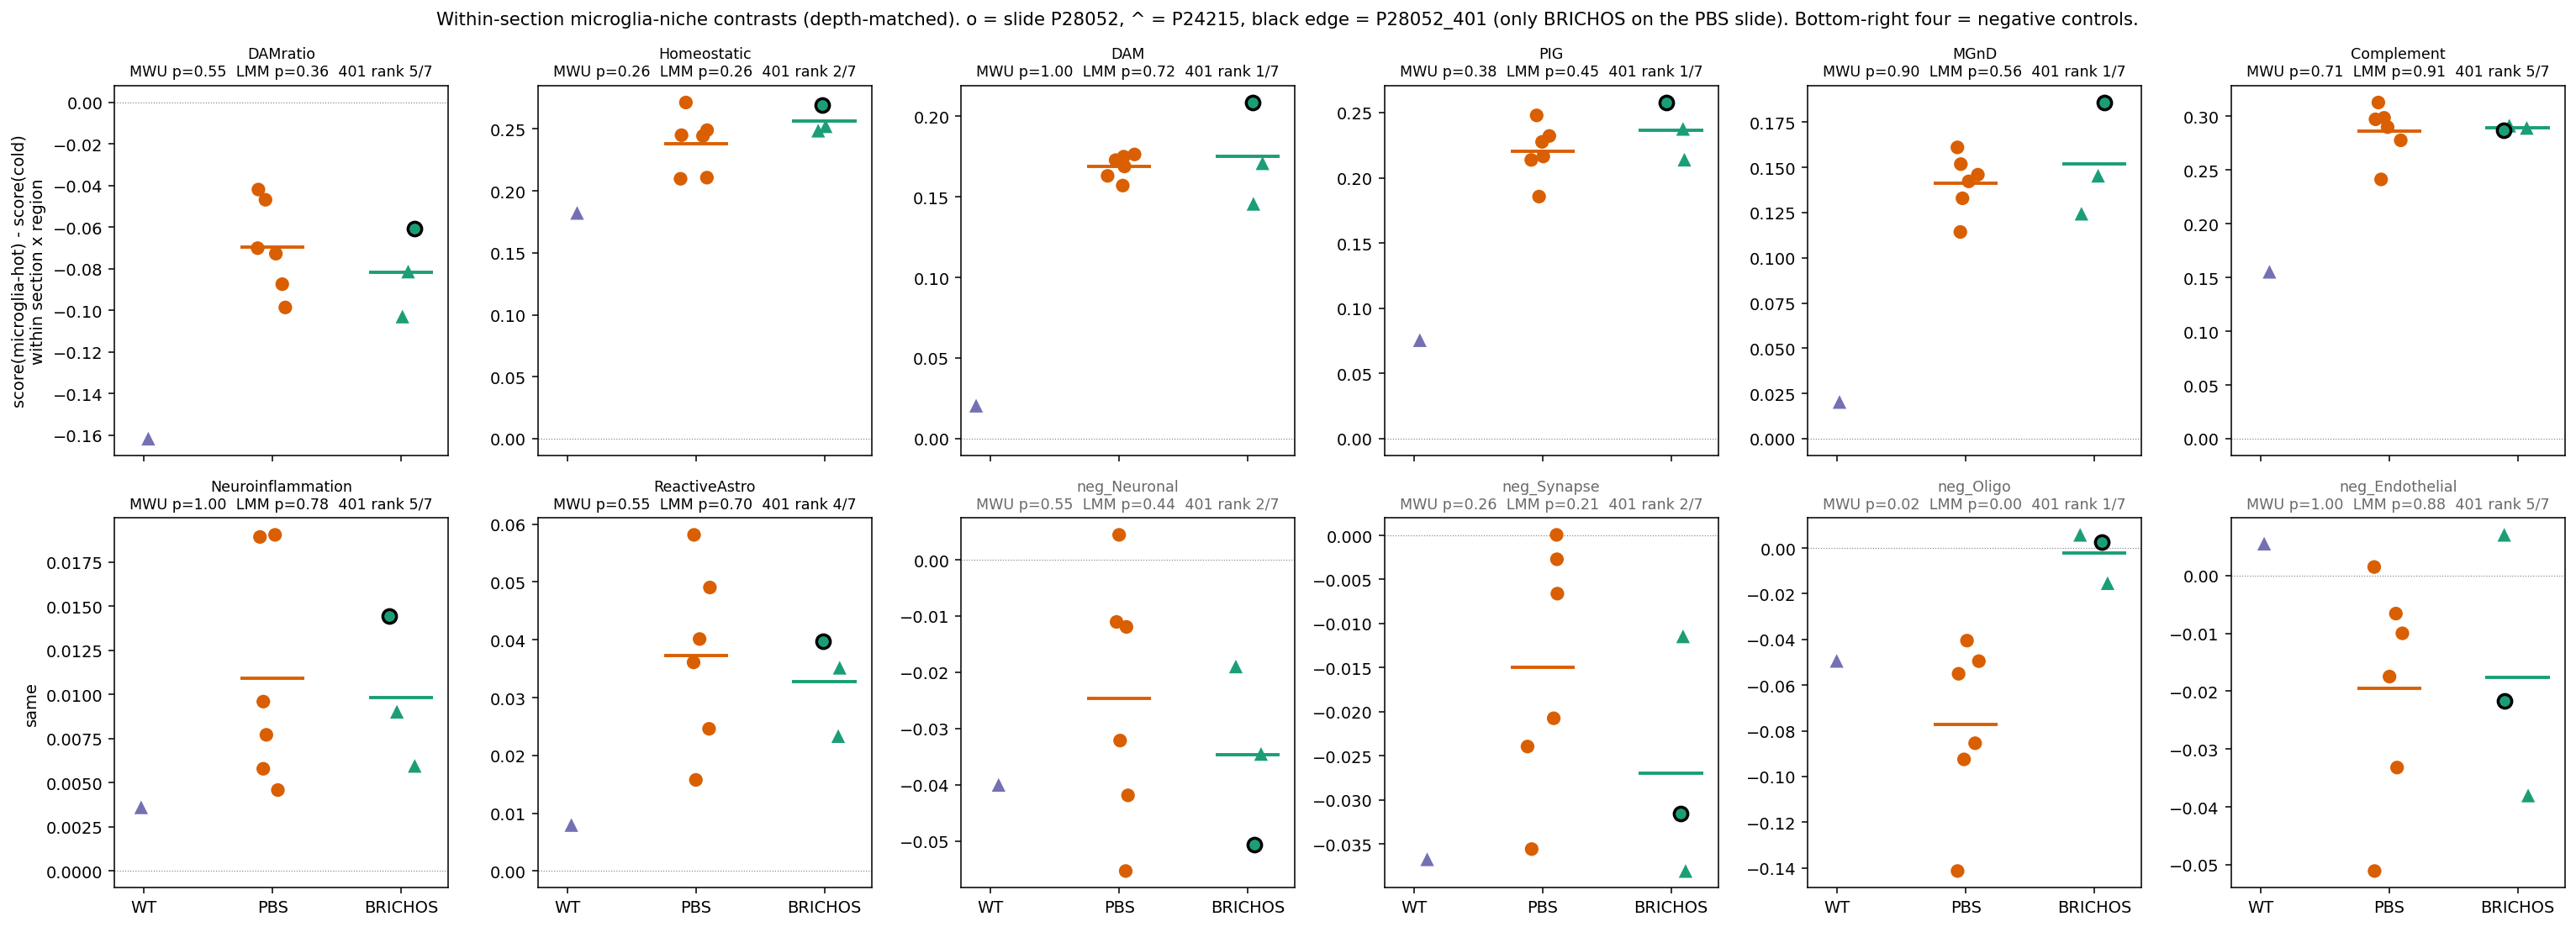

In [5]:
cs = pd.read_csv(RES / 'within_section' / 'contrast_stats.csv')
cols = ['score', 'WT', 'PBS_mean', 'BRICHOS_mean', 'delta', 'MWU_p', 'lmm_p', 'rank401_in_P28052', 'P24215_BRI_minus_WT']
print('hot − cold difference:')
display(cs[cs.kind == 'diff'][cols].set_index('score'))
print('slope on microglia rank (Homeostatic / DAMratio only):')
display(cs[(cs.kind == 'slope') & cs.score.isin(['Homeostatic', 'DAMratio'])][cols].set_index('score'))
display(Image(RES / 'within_section' / 'figs' / 'within_section_contrasts.png'))

**Reading.**

* The plaque-niche DAM/PIG response is strong in AD and **fully present under BRICHOS** (same-slide BRICHOS −
  WT ≈ +0.14 DAM, +0.15 PIG). No treatment effect on any microglial niche contrast; 401 has the *highest*
  DAM/PIG contrast on its slide (rank 1/7) — the opposite of "calming".
* The homeostatic slope is weakly higher in BRICHOS (MWU 0.095, LMM 0.068; 401 rank 1/7) — the only residue
  of the 03/10 homeostatic shift.
* The oligodendrocyte negative control fails (BRICHOS hot spots less oligo-depleted, LMM p = 0.003) — a
  lead or an artefact, unresolved.

## 4. Can a classifier tell PBS from BRICHOS? (03/12)

Leave-one-section-out; permutation null over all 84 BRICHOS labellings; slide-conditional test = rank of 401
among the 7 P28052 sections (floor p = 1/7). Three runs: original, depth-matched (downsampled to 5000 UMI,
immediate-early genes dropped, regions matched), and additionally anatomy genes removed.

In [6]:
runs = {'original': 'classifier', 'depth-matched': 'classifier_depth', 'depth + anatomy removed': 'classifier_noanat'}
rows = []
for name, d in runs.items():
    s = pd.read_csv(RES / d / 'loso_summary.csv').pivot(index='feature_set', columns='task', values='section_auc')
    p = pd.read_csv(RES / d / 'permutation_null.csv')
    pp = p.groupby('feature_set').apply(lambda g: (g.section_auc >= g[g.is_true].section_auc.iloc[0]).mean())
    r = pd.read_csv(RES / d / 'slide_conditional_401.csv')
    r401 = r[r.is_true].set_index('feature_set')['rank']
    for fs in s.index:
        rows.append(dict(run=name, features=fs, AUC_treatment=s.loc[fs, 'treatment'], perm_p=pp[fs],
                         AUC_slide=s.loc[fs, 'slide'], rank401_of7=int(r401[fs])))
clf = pd.DataFrame(rows).set_index(['run', 'features'])
display(clf)

AUC_treatment  perm_p  AUC_slide  rank401_of7
run                     features                                               
original                hvg               0.778   0.083      0.952            2
                        pca               0.889   0.048      0.905            1
                        qc                1.000   0.012      1.000            1
                        sig               0.611   0.321      0.667            1
depth-matched           hvg               0.722   0.071      0.810            2
                        pca               0.667   0.095      0.762            2
                        qc                0.667   0.262      0.952            7
                        sig               0.611   0.274      0.667            1
depth + anatomy removed hvg               0.667   0.095      0.810            2
                        pca               0.833   0.060      0.857            2
                        qc                0.667   0.298      1.000            6
                        sig               0.722   0.155      0.952            4

**Reading.** The original QC-only model (counts / genes / % ribo) separates treatment perfectly — because it
reads sequencing depth. After depth matching, treatment AUC falls to 0.6–0.8 and no feature set beats the
permutation null (p ≥ 0.06), while **slide stays predictable** (AUC 0.67–1.0, mostly ≥ 0.8). Treatment and slide model coefficients
correlate (r ≈ 0.6). Within P28052, 401 at best ranks 1–2 of 7 (minimum possible p = 0.14), with P28052_301 (a PBS
section) ranking alongside it in the expression models. **The classifier learns slide, not treatment.**

## 5. Regional rescue — the manuscript headline (03/14–16)

### 5a. A pure slide contrast mimics a rescue slope

The 03/02 rescue slope regresses BRICHOS−PBS LFC on the disease LFC (PBS − WT). Slide enters both with
opposite sign. Whole-section pseudobulk, PIG genes:

In [7]:
counts = pd.read_csv(TBL / 'pseudobulk_counts.tsv', sep='\t', index_col=0)
secc = counts.groupby(meta['sample']).sum()
secc = secc.loc[:, secc.sum() >= 100]
lc = np.log2(secc.div(secc.sum(1), axis=0) * 1e6 + 1)
dis = pd.read_csv(TBL / 'disease_signature.tsv', sep='\t', index_col=0).lfc
pig = lc.columns.intersection(PIG_CHEN2020).intersection(dis.index)
p28_pbs = [s for s in lc.index if s.startswith('P28052') and s != 'P28052_401']
contrasts = {
    'slide only (P24215 BRI − 401)':     lc.loc[['P24215_201', 'P24215_301']].mean() - lc.loc['P28052_401'],
    'treatment only (401 − P28052 PBS)': lc.loc['P28052_401'] - lc.loc[p28_pbs].mean(),
    'original (all BRI − all PBS)':      lc.loc[['P24215_201', 'P24215_301', 'P28052_401']].mean() - lc.loc[p28_pbs].mean(),
}
display(pd.DataFrame({k: dict(PIG_rescue_slope=np.polyfit(dis[pig], v[pig], 1)[0],
                              frac_PIG_down=np.mean(v[pig] < 0)) for k, v in contrasts.items()}).T)

,PIG_rescue_slope,frac_PIG_down
slide only (P24215 BRI − 401),-0.098,0.365
treatment only (401 − P28052 PBS),0.026,0.673
original (all BRI − all PBS),-0.040,0.596


**Reading.** The slide contrast alone gives a steeper "rescue" slope (−0.10) than the real comparison (−0.04);
401 within its own slide gives +0.03. The slope statistic is slide-contaminated. (Concordance is not: the
slide pushes PIG genes *up*, and 401's 67 % PIG-down ranks only 2/7 among P28052 sections.)

### 5b. Within-section and model-based slide removal

* **within-section** — each section centred on its own 7-region mean; cancels region-uniform slide, but also
  any global rescue (only the regional *profile* remains).
* **RUVg_k1** — removes one factor learnt from 1000 stable non-disease control genes; the factor tracks slide
  (r = 0.97) and brings the region-uniform slide contrast below same-slide noise. Assumes BRICHOS does not
  change the control genes.
* **tech** — GC / length / expression model of the slide contrast; explains ~0 % (CV R² 0.01), so the slide
  effect is not a technical capture bias and nothing is removed.

rescue-slope permutation p per region (floor 1/84 = 0.012 unless noted)


PIG                                                                         data                                                                      
method                  none   tech RUVs_k2 RUVg_k1 RUVg_k2 within-section 401 only (p floor 0.14)   none   tech RUVs_k2 RUVg_k1 RUVg_k2 within-section 401 only (p floor 0.14)
region                                                                                                                                                                         
Infragranular layers   0.060  0.060   0.179   0.024   0.167          0.250                   1.000  0.012  0.012   0.012   0.012   0.012          0.179                   0.286
Meninges               0.214  0.238   0.345   0.179   0.393          0.381                   0.571  0.107  0.131   0.131   0.036   0.131          0.190                   0.714
Olfactory areas        0.179  0.179   0.214   0.155   0.226          0.226                   0.571  0.107  0.143   0.119   0.048   0.095          0.167                   0.571
Supragranualar layers  0.060  0.060   0.143   0.024   0.119          0.214                   1.000  0.179  0.179   0.405   0.012   0.155          0.774                   0.857
Hypothalamus           0.417  0.452   0.524   0.524   0.631          0.631                   0.286  0.262  0.262   0.274   0.262   0.298          0.595                   0.143
Caudoputamen           0.214  0.250   0.381   0.179   0.226          0.429                   0.571  0.440  0.440   0.536   0.226   0.238          0.702                   0.286
Corpus callosum        0.774  0.774   0.893   0.726   0.893          0.917                   0.429  0.810  0.762   0.726   0.619   0.798          0.905                   0.571

,slide_uniform_vs_noise,slide_regional_vs_noise,max_abs_r_factor_slide
method,,,
none,1.694,1.298,NaN
tech,1.692,1.275,NaN
RUVs_k1,1.474,1.164,0.129
RUVg_k1,0.419,1.265,0.969
RUVs_k2,1.130,1.134,0.749
RUVg_k2,0.296,1.223,0.969


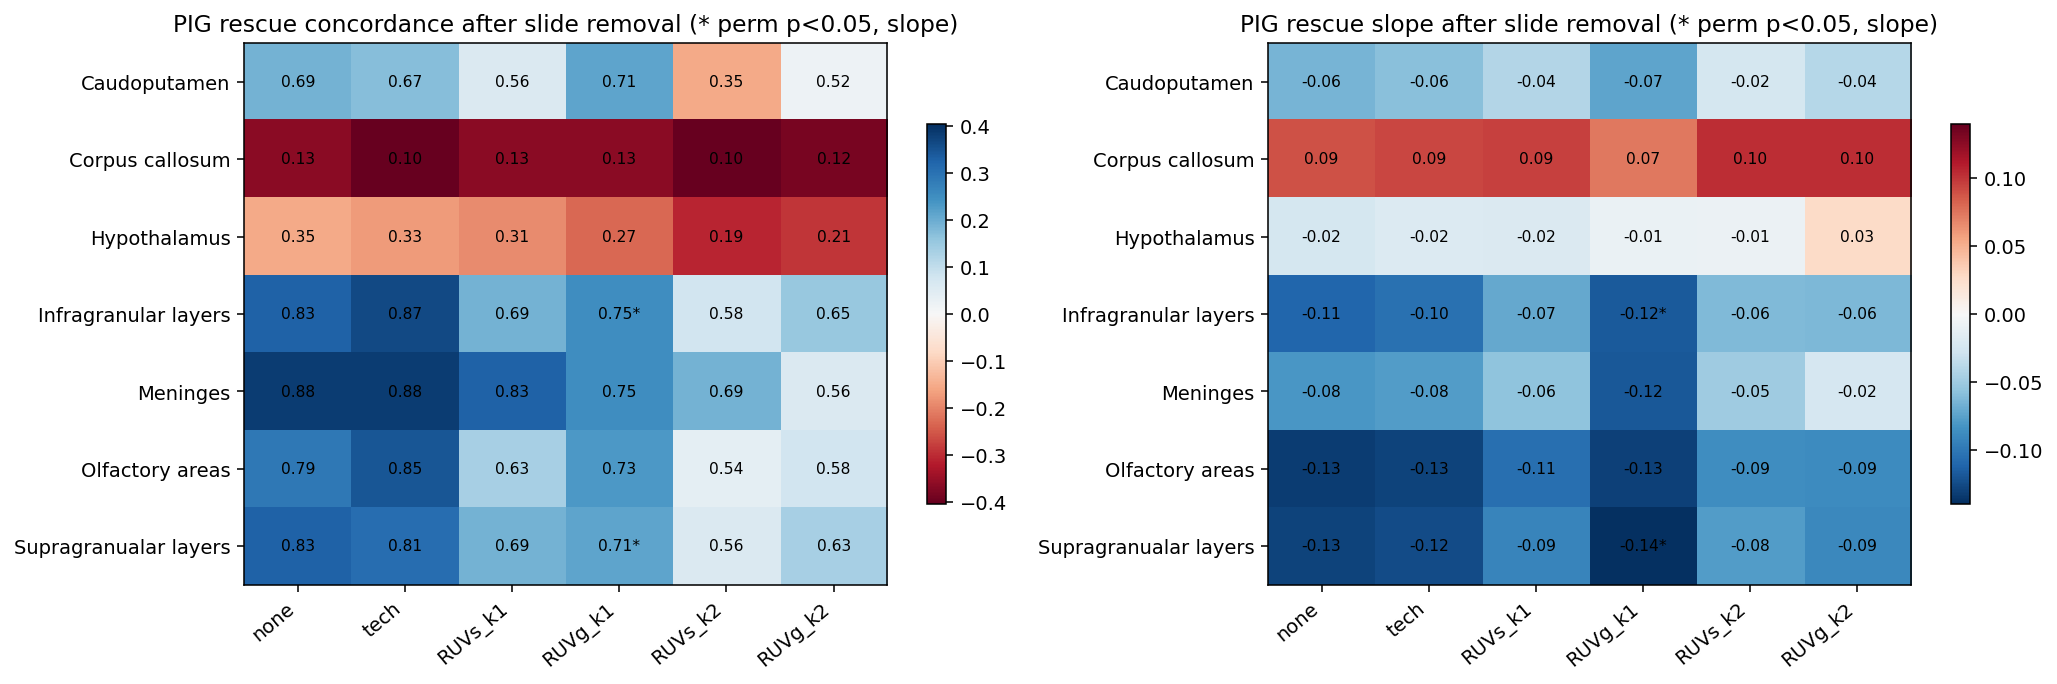

In [8]:
ws = pd.read_csv(RES / 'within_section_rescue' / 'rescue_within_section.csv')
sr = pd.read_csv(RES / 'slide_removal' / 'rescue_after_slide_removal.csv')
tab = []
for gs in ['PIG', 'data']:
    a = sr[sr.gene_set == gs].pivot(index='region', columns='method', values='perm_p_slope')[['none', 'tech', 'RUVs_k2', 'RUVg_k1', 'RUVg_k2']]
    b = ws[ws.gene_set == gs].pivot(index='region', columns='design', values='perm_p_slope')
    a['within-section'] = b['within-section (centred)']
    a['401 only (p floor 0.14)'] = b['within-slide 401 vs P28052 PBS']
    a.columns = pd.MultiIndex.from_product([[gs], a.columns])
    tab.append(a)
print('rescue-slope permutation p per region (floor 1/84 = 0.012 unless noted)')
display(pd.concat(tab, axis=1).sort_values(('data', 'none')))
display(pd.read_csv(RES / 'slide_removal' / 'correction_diagnostics.csv').set_index('method')[
    ['slide_uniform_vs_noise', 'slide_regional_vs_noise', 'max_abs_r_factor_slide']])
display(Image(RES / 'slide_removal' / 'rescue_after_slide_removal.png'))

**Reading.**

* **Infragranular cortex** is the most robust result: at the permutation floor (p = 0.012) under every
  correction with the data-driven gene set, and p = 0.024 with PIG after RUVg_k1. Supragranular cortex
  reaches p = 0.012–0.024 after RUVg_k1 but weakens with two factors.
* Corpus callosum and hypothalamus remain non-responders under every method.
* Within-section centring keeps the regional ranking (cortex / meninges / olfactory > CC / hypothalamus) but
  nothing reaches p < 0.05.
* **401 alone does not show the cortical preference** (its most "rescued" regions are corpus callosum and
  caudoputamen). The region-specific part of the slide effect (~1.2–1.3× same-slide noise) is not removed by
  any method. Either 401 is just a different animal or the slide acts unequally across regions — not
  resolvable with n = 1.

## 6. What this means

**For the manuscript**

* Present the treatment results as **hypothesis-generating**, with the confound stated up front (Methods +
  a supplementary figure built from sections 2–5 here) — reviewers will see it in the sample table.
* Defensible core: (i) a clear AD disease response that BRICHOS does not abolish; (ii) a modest cortical
  rescue signal that survives control-gene slide removal; (iii) no change in microglia abundance.
* Drop or recast: BRICHOS lowers microglia; BRICHOS calms plaque-niche microglia; uncorrected rescue slopes.

Draft caveat paragraph:

> Because PBS and BRICHOS sections were largely processed on different Visium slides, treatment and slide
> are partially confounded. Microglial abundance and state differences between treatments did not survive
> adjustment for slide. The regional rescue was preserved in infragranular cortex after control-gene-based
> removal of unwanted variation (RUVg, k = 1; the inferred factor tracked slide, r = 0.97; permutation
> p = 0.012–0.024), whereas within-section difference-in-differences preserved the regional ranking without
> reaching significance. The single BRICHOS section processed alongside PBS sections did not reproduce the
> cortical preference, so these results should be regarded as provisional pending a batch-balanced replication.

**What would actually fix it**

1. **Remaining tissue** — even 1–2 PBS sections on the same slide as BRICHOS sections would bridge the design.
   This is by far the most valuable experiment.
2. **Other samples from the same processing batches** (P24215 / P28052 are likely NGI project IDs) — any
   shared tissue sequenced in both lets the batch effect be measured directly.
3. **Orthogonal validation independent of the slides** — IBA1 / CD68 / P2RY12 / plaque staining or qPCR in
   cortex.